# wav2vec2 + Qwen3-0.6B: train và so sánh có kiểm soát

Audio → wav2vec2 → đối chiếu âm chuẩn → Qwen → hướng dẫn tiếng Anh.
Model âm thanh và Qwen được train riêng, chạy lần lượt trên GPU. Không dùng Qwen2-Audio.
Nhãn hướng dẫn gốc từ [L2-Arctic-plus / Findings of EACL 2026](https://aclanthology.org/2026.findings-eacl.190/).
Train feedback do tác giả tạo bằng GPT-4o; 900 test reference được tác giả kiểm tra bằng người.
Không yêu cầu bạn duyệt 300 template tự tạo trước đó.

**Kernel: MDD (.venv).** Các cell xem dữ liệu/tiến trình có thể chạy ngay.
Cell **CHẠY TRAIN** mặc định có `RUN_TRAIN=False`; bạn tự đổi thành `True` khi muốn train. Run All không khởi động train.
Nếu pipeline đã chạy nền, cell chỉ hiển thị tiến trình, không tạo lượt train thứ hai.

In [1]:
from pathlib import Path
import json, sys, os, subprocess, math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Audio, Markdown, Image, HTML
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/run_cascade_training.py').is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from scripts.prepare_cascade_data import check_common_split
CONFIG=ROOT/'configs/cascade_l2arctic_plus.json'
config=json.loads(CONFIG.read_text(encoding='utf-8'))
PYTHON=ROOT/('.venv/Scripts/python.exe' if os.name=='nt' else '.venv/bin/python')
if not PYTHON.is_file(): PYTHON=Path(sys.executable)
REPORTS=ROOT/config['report_root']; RUNS=ROOT/config['run_root']
def run_script(*args):
    command=[str(PYTHON),'-X','utf8','-u',*[str(value) for value in args]]
    print(subprocess.list2cmdline(command))
    subprocess.run(command,cwd=ROOT,check=True)
print('Project:',ROOT)
print('Reports:',REPORTS)

Project: D:\NCC\MDD
Reports: D:\NCC\MDD\data\generated\cascade-l2arctic-plus-seed42


## 1. Môi trường và lệnh cài đặt

Giữ bản Torch CUDA đang dùng. Cài phần thiếu bằng Python của kernel, không thay Torch bằng bản CPU.
Các lệnh dưới được in ra để dùng lại khi chuyển máy.

In [2]:
from importlib.metadata import version
import torch
display(pd.DataFrame([{'package':name,'version':version(name)} for name in ['torch','transformers','peft','accelerate','bitsandbytes','sacrebleu','rouge-score']]))
print('CUDA:',torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(),'· GiB:',round(torch.cuda.get_device_properties(0).total_memory/2**30,2))
for requirement in ['requirements/training.txt','requirements/feedback.txt','requirements/feedback-evaluation.txt','requirements/notebook.txt']:
    print(subprocess.list2cmdline([str(PYTHON),'-m','pip','install','-r',requirement]))

,package,version
0,torch,2.7.1+cu126
1,transformers,4.57.6
2,peft,0.17.1
3,accelerate,1.10.1
4,bitsandbytes,0.48.1
5,sacrebleu,2.5.1
6,rouge-score,0.1.2


CUDA: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU · GiB: 4.0
D:\NCC\MDD\.venv\Scripts\python.exe -m pip install -r requirements/training.txt
D:\NCC\MDD\.venv\Scripts\python.exe -m pip install -r requirements/feedback.txt
D:\NCC\MDD\.venv\Scripts\python.exe -m pip install -r requirements/feedback-evaluation.txt
D:\NCC\MDD\.venv\Scripts\python.exe -m pip install -r requirements/notebook.txt


## 2. Split chung và kiểm tra rò rỉ

Qwen: 2.249 train / 450 validation / 900 test. Validation: HJK, LXC, PNV.
wav2vec2 A: 1.949 source train / 300 source validation. B: 300 target train,
150 target validation, source replay 50%. Người Việt test là TLV (150 câu);
toàn bộ test chung còn có 750 câu của năm người nói ngoài Việt Nam.

Không dùng checkpoint A/B cũ: 750/900 test chung từng xuất hiện trong source train cũ.
A mới khởi tạo từ wav2vec2-base, với phone head mới. Vocabulary âm vị được khai báo trước,
không fit từ test. Câu đọc có thể chung giữa các người nói: đây là speaker holdout.

In [3]:
if not (ROOT/config['protocol_dir']/'protocol.json').is_file():
    run_script('scripts/prepare_cascade_data.py')
protocol,splits,qwen_manifest=check_common_split(config)
readiness=json.loads((REPORTS/'data_readiness.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'split':name,'utterances':value} for name,value in protocol['joint_counts'].items()]))
display(pd.Series(readiness,name='readiness'))
print('Qwen speakers:',qwen_manifest['speakers'])
assert readiness['test_train_overlap']==readiness['test_validation_overlap']==0

,split,utterances
0,train,2249
1,validation,450
2,test,900


protocol_id                                                      l2arctic-plus-cascade-v1
source_commit                                    e8c7684c545d94f2419fc4621e745236c192a353
joint_counts                              {'train': 2249, 'validation': 450, 'test': 900}
audio_source_train                                                                   1949
audio_source_validation                                                               300
audio_target_counts                        {'train': 300, 'validation': 150, 'test': 150}
test_train_overlap                                                                      0
test_validation_overlap                                                                 0
audio_hashes_verified                                                                True
qwen_token_exclusions                                                                  []
old_source_train_overlap_with_new_test                                                750
old_checkp

Qwen speakers: {'train': ['ABA', 'ASI', 'BWC', 'EBVS', 'ERMS', 'HKK', 'HQTV', 'MBMPS', 'NCC', 'RRBI', 'SKA', 'SVBI', 'THV', 'YBAA', 'YDCK'], 'validation': ['HJK', 'LXC', 'PNV'], 'test': ['NJS', 'TLV', 'TNI', 'TXHC', 'YKWK', 'ZHAA']}


## 3. Visualization dữ liệu thật

,samples,speakers,hours,max_tokens
split,,,,
test,900,6,0.877178,1398
train,2249,15,2.341134,1750
validation,450,3,0.445147,1438


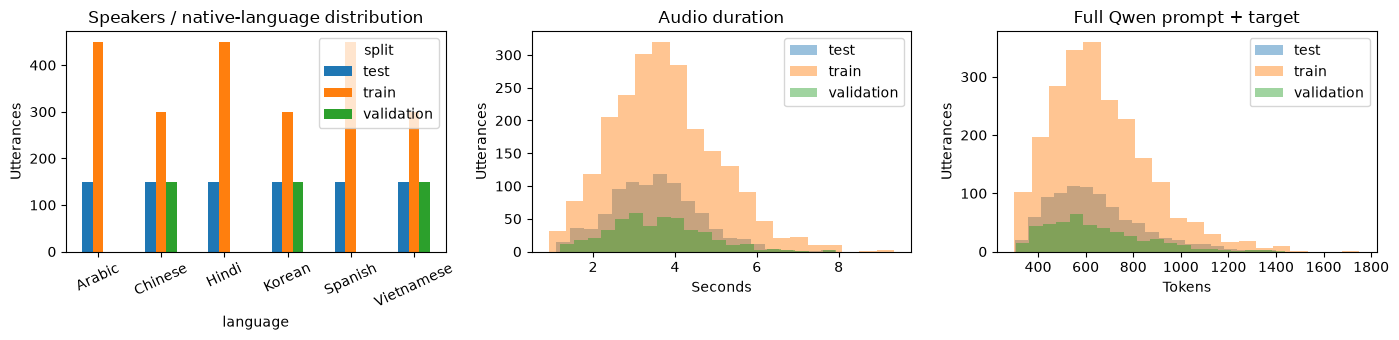

In [4]:
annotations={r['utterance_id']:r for r in (json.loads(line) for line in (ROOT/config['processed_dir']/'annotations.jsonl').read_text(encoding='utf-8').splitlines() if line.strip())}
frames=[]
qwen_config=json.loads((ROOT/config['feedback_config']).read_text(encoding='utf-8'))
for split in ['train','validation','test']:
    rows=[json.loads(line) for line in (ROOT/qwen_config['dataset_dir']/f'{split}.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
    for row in rows:
        a=annotations[row['utterance_id']]
        frames.append({'id':row['utterance_id'],'split':split,'speaker':row['speaker_id'],'language':a['native_language'],'seconds':a['duration_sec'],
            'canonical_phones':len(a['canonical_phones']),'perceived_phones':len(a['perceived_phones']),
            'gold_phone_errors':len(a['gold_error_events']),'tokens':row['total_tokens'],'target_tokens':row['target_tokens']})
frame=pd.DataFrame(frames)
display(frame.groupby('split').agg(samples=('id','size'),speakers=('speaker','nunique'),hours=('seconds',lambda x:x.sum()/3600),max_tokens=('tokens','max')))
fig,axes=plt.subplots(1,3,figsize=(14,3.5))
frame.groupby(['language','split']).size().unstack(fill_value=0).plot.bar(ax=axes[0],rot=25)
for name,part in frame.groupby('split'):
    axes[1].hist(part['seconds'],bins=20,alpha=.45,label=name)
    axes[2].hist(part['tokens'],bins=20,alpha=.45,label=name)
axes[0].set(title='Speakers / native-language distribution',ylabel='Utterances')
axes[1].set(title='Audio duration',xlabel='Seconds',ylabel='Utterances');axes[1].legend()
axes[2].set(title='Full Qwen prompt + target',xlabel='Tokens',ylabel='Utterances');axes[2].legend()
fig.tight_layout();display(fig);plt.close(fig)

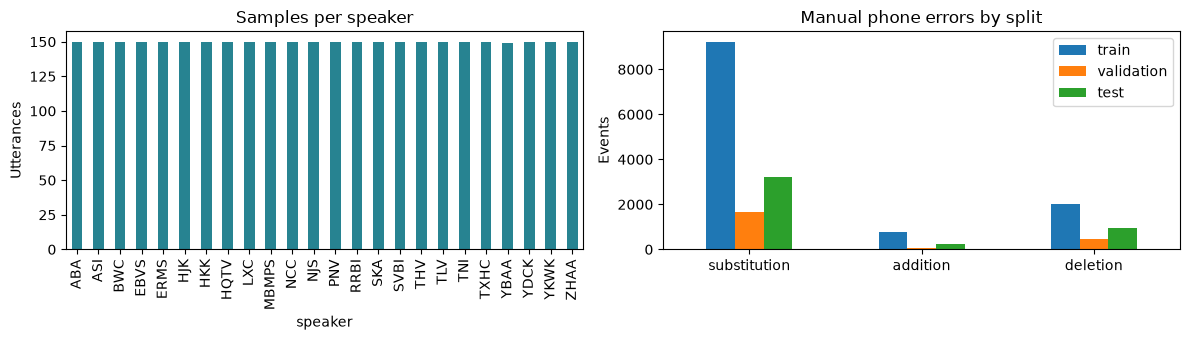

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
frame.groupby('speaker')['id'].count().plot.bar(ax=axes[0],color='#278391')
error_counts={split:{} for split in ['train','validation','test']}
for row in frames:
    for event in annotations[row['id']]['gold_error_events']:
        key=event['kind']; group=error_counts[row['split']]
        group[key]=group.get(key,0)+1
pd.DataFrame(error_counts).fillna(0).plot.bar(ax=axes[1],rot=0)
axes[0].set(title='Samples per speaker',ylabel='Utterances')
axes[1].set(title='Manual phone errors by split',ylabel='Events')
fig.tight_layout();display(fig);plt.close(fig)

## 4. Một ví dụ audio, nhãn và hướng dẫn gốc

Đây là một mẫu train được chọn cố định. Audio là đầu vào wav2vec2; Qwen chỉ nhận
câu tham chiếu và nhãn âm vị/sai khác. Ở lượt oracle, dùng nhãn công bố; ở lượt
cascade, thay bằng âm dự đoán thật. Nhãn perceived/gold chỉ được dùng để train/chấm,
không đưa vào nhánh nhận diện audio khi suy luận.

In [6]:
samples=[json.loads(line) for line in (ROOT/qwen_config['dataset_dir']/'train.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
sample=samples[0]; annotation=annotations[sample['utterance_id']]
print(sample['utterance_id'],sample['reference_text'])
display(Audio(filename=str(ROOT/annotation['audio_path']),embed=True))
display(pd.DataFrame(annotation['gold_error_events']))
display(pd.DataFrame([{'word':word,**pair} for word,pairs in sample['feedback'].items() for pair in pairs]))

ABA/arctic_a0501 You're joking me sir the other managed to articulate


,canonical_index,end_sec,expected_phone,kind,observed_phone,perceived_index,position,raw_label,start_sec,type,word_index
0,3.0,0.390000,JH,substitution,ZH,3,3,"JH,ZH,s",0.230000,substitution,1
1,NaN,0.661581,None,addition,G,8,8,"sil,G,a",0.638257,addition,1
2,NaN,0.710000,None,addition,AH,9,8,"sil,AH0,a",0.661581,addition,1
3,11.0,1.240000,ER,substitution,err,13,11,"ER1,err,s",1.020000,substitution,3
4,15.0,2.050000,DH,substitution,Z,17,15,"DH,Z,s",1.940000,substitution,5
5,16.0,2.150000,ER,substitution,err,18,16,"ER0,err,s",2.050000,substitution,5
6,21.0,2.570000,JH,substitution,ZH,23,21,"JH,ZH,s",2.500000,substitution,6
7,26.0,3.200000,R,substitution,R*,28,26,"R, R*, s",3.110000,substitution,8
8,33.0,3.740000,EY,substitution,EH,35,33,"EY2,EH,s",3.660000,substitution,8


,word,issue,suggestion
0,joking,"""JH"" was replaced with ""ZH"", indicating a subs...","Practice the difference between /JH/ as in ""JO..."
1,joking,"An extra ""G"" sound was added, indicating an ad...","Focus on stopping after the /NG/ as in ""KING"" ..."
2,joking,"An extra ""AH"" sound was added, indicating an a...",Avoid adding extra vowel sounds after completi...
3,sir,"Unclear pronunciation, ""ER"" perceived with unc...","Practice /ER/ as in ""SIR"" (/S ER/) to add clarity"
4,other,"""DH"" was replaced with ""Z"", indicating a subst...","Practice unvoiced /DH/ as in ""THIS"" (/DH IH S/..."
5,other,"Unclear pronunciation, ""ER"" perceived with unc...","Practice /ER/ as in ""HER"" (/HH ER/) for more d..."
6,managed,"""JH"" was replaced with ""ZH"", indicating a subs...","Practice the distinction between /JH/ as in ""J..."
7,articulate,"""R"" was replaced with a foreign-accented ""R*"",...","Practice the American /R/ sound as in ""RED"" (/..."
8,articulate,"""EY"" was replaced with ""EH"", indicating a subs...","Practice the distinction between /EY/ as in ""D..."


## 5. Bốn cấu hình và chỉ số

A là source-trained CTC baseline, B là sau thích ứng Việt. Q0 là Qwen gốc,
Q1 là sau LoRA. Cả bốn cùng 900 bản thu, cùng câu tham chiếu và cấu hình sinh greedy.
Báo cáo oracle riêng để thấy mức suy giảm khi dùng lỗi dự đoán thực.

Audio: PER, precision/recall/F1, FRR và word F1 theo scorer đã khóa.
Feedback: JSON hợp lệ, từ được tham chiếu đúng, BLEU-2 và ROUGE-L của suggestion,
NLL/perplexity, latency. F1 của feedback là **word-key coverage**, không phải phone F1.
JSON sai, model hết token, hoặc input không gán được từ đều giữ trong mẫu số.
Delta ROUGE-L có paired bootstrap 95% theo speaker; một seed không đo biến thiên giữa seed train.
Các chỉ số này chưa tự chứng minh người học tiến bộ hay mọi lời hướng dẫn đều đúng ngữ âm.

In [7]:
display(pd.DataFrame([{'case':a+'_'+q,'audio':a,'Qwen':q,'input':'Predicted phones'} for a in ['A','B'] for q in ['Q0','Q1']]))
display(pd.Series(json.loads((ROOT/config['feedback_eval_config']).read_text(encoding='utf-8')),name='locked_evaluation'))
for name,path in {**config['audio_configs'],'Q':config['feedback_config']}.items():
    print(name,json.loads((ROOT/path).read_text(encoding='utf-8')))

,case,audio,Qwen,input
0,A_Q0,A,Q0,Predicted phones
1,A_Q1,A,Q1,Predicted phones
2,B_Q0,B,Q0,Predicted phones
3,B_Q1,B,Q1,Predicted phones


protocol_id                                 l2arctic-plus-cascade-feedback-v1
task                                     annotated_phones_to_english_feedback
split                                                                    test
generation                  {'do_sample': False, 'num_beams': 1, 'max_new_...
context_length                                                           4096
seed                                                                       42
quantization                                                none-bf16-or-fp16
primary_metric                      suggestion_rougeL_on_reference_error_rows
bootstrap_repetitions                                                    2000
bootstrap_cluster                                                     speaker
metrics_scope               Oracle coaching and real predicted-phone casca...
failure_policy              No repair or template fallback; invalid output...
checkpoint_selection        Minimum validation loss; test is nev

A {'stage': 'A', 'purpose': 'scientific_training', 'seed': 42, 'model_path': 'models/pretrained/wav2vec2-base', 'protocol_dir': 'data/protocol/l2arctic-plus-cascade-v1', 'annotations': 'data/processed/l2arctic-plus-cascade-v1/annotations.jsonl', 'vocab': 'data/processed/l2arctic-plus-cascade-v1/vocab.json', 'normalization': 'data/processed/l2arctic-plus-cascade-v1/normalization.json', 'device': 'cuda', 'mixed_precision': 'fp16', 'cpu_threads': 4, 'batch_size': 1, 'gradient_accumulation_steps': 4, 'max_steps': 2000, 'eval_every': 250, 'checkpoint_every': 50, 'backbone_learning_rate': 3e-05, 'head_learning_rate': 0.0003, 'freeze_feature_encoder': True, 'freeze_backbone': False, 'gradient_checkpointing': True, 'max_train_samples': None, 'max_eval_samples': None, 'max_audio_seconds': None, 'selection_metric': 'f1', 'save_optimizer': True, 'fold': 1}
B {'stage': 'B', 'purpose': 'scientific_training', 'seed': 42, 'fold': 1, 'model_path': 'models/pretrained/wav2vec2-base', 'protocol_dir': 'da

## 6. Kiểm tra kỹ thuật trước train chính

Qwen dùng QLoRA NF4, full prompt, assistant-only loss. Projection từ vựng tính theo
chunk và checkpoint để giữ loss/gradient tương đương, giảm peak VRAM cho target dài.
Smoke lưu riêng trong `runs/local-checks/`; không lấy adapter này làm kết quả sau train.
Các report kỹ thuật dưới đây không được dùng để kết luận cải thiện chất lượng.

In [8]:
technical=[]
for path in sorted((ROOT/'runs/local-checks').glob('l2plus-*/training_provenance.json')):
    r=json.loads(path.read_text(encoding='utf-8'))
    if r.get('purpose')=='technical_smoke' and r.get('effective_config',{}).get('warmup_ratio')==0:
        technical.append({'run':path.parent.name,'status':r['status'],'optimizer_steps':r.get('global_step'),'samples':r.get('samples_used'),
            'peak_GiB':r.get('peak_allocated_bytes',0)/2**30,'validation_loss':r.get('best_validation_loss')})
display(pd.DataFrame(technical))
run_script('scripts/train_feedback_model.py','--config',config['feedback_config'],'--check-data-only')

,run,status,optimizer_steps,samples,peak_GiB,validation_loss
0,l2plus-20261021T044824803255Z,completed,1,"{'train': 8, 'validation': 1}",1.820535,1.604515


D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 -u scripts/train_feedback_model.py --config configs/cascade_feedback_qlora.json --check-data-only


## 7. CHẠY TRAIN / RESUME toàn bộ pipeline

Cell này chạy A (2.000 updates) → B (400 updates) → Qwen (3 epochs) → hai lượt
audio test → hai lượt Qwen oracle → bốn lượt cascade → report. Đây là tác vụ dài;
GPU được dùng lần lượt. Chọn checkpoint audio bằng validation F1, Qwen bằng validation loss.
Test không chọn checkpoint hay thay recipe. Log/checkpoint/optimizer được giữ để resume.
Nếu muốn tách giai đoạn, CLI có `--phase train` và `--phase evaluate`.

In [ ]:
RUN_TRAIN = False
if not RUN_TRAIN:
    print('Chỉ xem dữ liệu/trạng thái. Bạn tự bật cờ True khi muốn bắt đầu train.')
else:
    import psutil
    status_path=REPORTS/'pipeline_status.json'
    status=json.loads(status_path.read_text(encoding='utf-8')) if status_path.is_file() else {}
    if status.get('status')=='running' and psutil.pid_exists(status.get('pid',-1)):
        print('Pipeline đang chạy nền; xem cell tiến trình bên dưới.')
        display(pd.Series(status))
    elif status.get('status')=='completed' and status.get('phase')=='all':
        print('Pipeline đã hoàn thành; mở report hoặc chạy lại cell báo cáo.')
    else:
        run_script('scripts/run_cascade_training.py','--phase','all')

## 8. Tiến trình hiện tại — chạy lại cell này để cập nhật

In [9]:
status_path=REPORTS/'pipeline_status.json'
status=json.loads(status_path.read_text(encoding='utf-8')) if status_path.is_file() else {'status':'not_started'}
display(pd.Series(status,name='pipeline'))
if status.get('log') and Path(status['log']).is_file():
    print(chr(10).join(Path(status['log']).read_text(encoding='utf-8',errors='replace').splitlines()[-12:]))

status                                                       running
phase                                                            all
started_at_utc                      2026-10-21T04:56:37.924268+00:00
pid                                                             6268
total_commands                                                    12
command_index                                                      1
current_command                                              train_A
argv               [D:\NCC\MDD\.venv\Scripts\python.exe, -X, utf8...
log                D:\NCC\MDD\data\generated\cascade-l2arctic-plu...
updated_at_utc                      2026-10-21T04:57:03.954245+00:00
child_pid                                                      11200
Name: pipeline, dtype: object

{"step": 24, "loss": 4.135638236999512, "gradient_norm": 1.8520736694335938, "elapsed_seconds": 13.06300000000192, "seen_samples": {"source": 96, "target": 0}, "seen_audio_seconds": {"source": 363.2031519274377, "target": 0.0}, "lr": {"backbone": 3e-05, "phone_head": 0.0003}, "created_at": "2026-10-21T04:56:59.517407+00:00"}
{"step": 25, "loss": 4.12366509437561, "gradient_norm": 2.47768235206604, "elapsed_seconds": 13.610000000000582, "seen_samples": {"source": 100, "target": 0}, "seen_audio_seconds": {"source": 379.3277551020409, "target": 0.0}, "lr": {"backbone": 3e-05, "phone_head": 0.0003}, "created_at": "2026-10-21T04:57:00.064795+00:00"}
{"step": 26, "loss": 3.9659876823425293, "gradient_norm": 1.7796334028244019, "elapsed_seconds": 14.110000000000582, "seen_samples": {"source": 104, "target": 0}, "seen_audio_seconds": {"source": 394.9428571428572, "target": 0.0}, "lr": {"backbone": 3e-05, "phone_head": 0.0003}, "created_at": "2026-10-21T04:57:00.563211+00:00"}
{"step": 27, "los

## 9. Learning curves và kết quả trước/sau

Chạy lại cell để đọc log thật. Khi các lượt test chưa xong, bảng sẽ ghi đang chờ;
không có điểm sau train giả định. Report xuất JSON, CSV, PNG, SVG và HTML tự chứa.
Ví dụ phản hồi được chọn cố định theo speaker, không chọn riêng những mẫu cải thiện.

D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 -u scripts/report_cascade.py


Trạng thái: awaiting_evaluations
Còn chờ: ['A', 'B'] ['A_Q0', 'A_Q1', 'B_Q0', 'B_Q1', 'oracle_Q0', 'oracle_Q1']


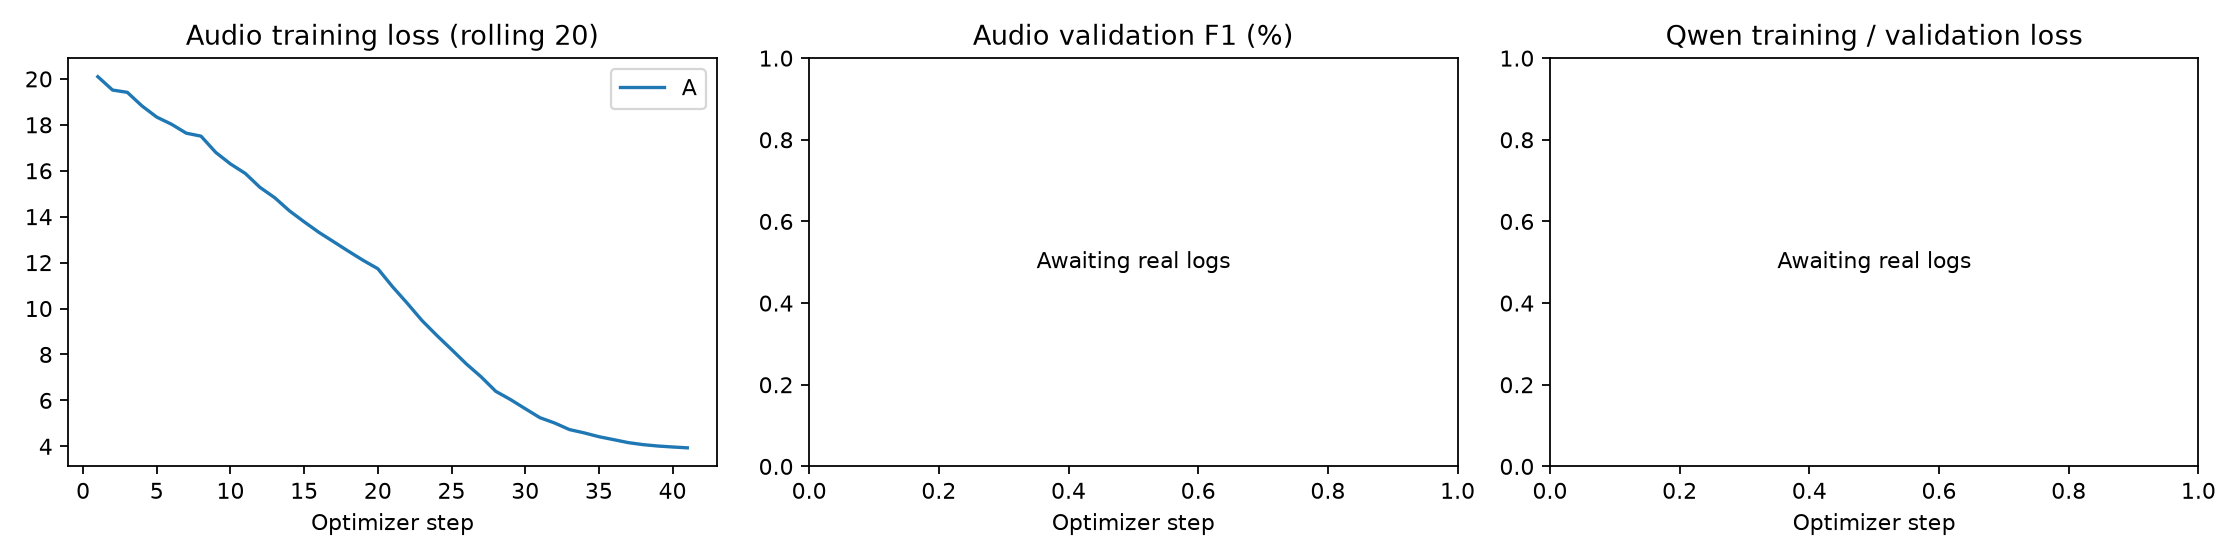

HTML: D:\NCC\MDD\data\generated\cascade-l2arctic-plus-seed42\report\report.html


In [10]:
run_script('scripts/report_cascade.py')
summary=json.loads((REPORTS/'report/comparison.json').read_text(encoding='utf-8'))
print('Trạng thái:',summary['status'])
print('Còn chờ:',summary['missing_audio'],summary['missing_feedback'])
for filename in ['audio_comparison.csv','feedback_comparison.csv','feedback_by_speaker.csv']:
    path=REPORTS/'report'/filename
    if path.is_file(): display(pd.read_csv(path))
for filename in ['training_curves.png','before_after.png']:
    path=REPORTS/'report'/filename
    if path.is_file(): display(Image(filename=str(path)))
if summary.get('paired_intervals'): display(pd.DataFrame(summary['paired_intervals']).T)
print('HTML:',REPORTS/'report/report.html')